In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
uploaded = files.upload()


Saving Automobile_data.csv to Automobile_data.csv


In [4]:
df = pd.read_csv("/content/Automobile_data.csv")

In [5]:
print("First Five Records:")
display(df.head())

First Five Records:


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


In [6]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(205, 26)


In [7]:
print("\nRequired Features:")
print("power_to_weight_ratio:", 'power_to_weight_ratio' in df.columns)
print("combined_mpg:", 'combined_mpg' in df.columns)


Required Features:
power_to_weight_ratio: False
combined_mpg: False


In [8]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']


# Horsepower vs Price

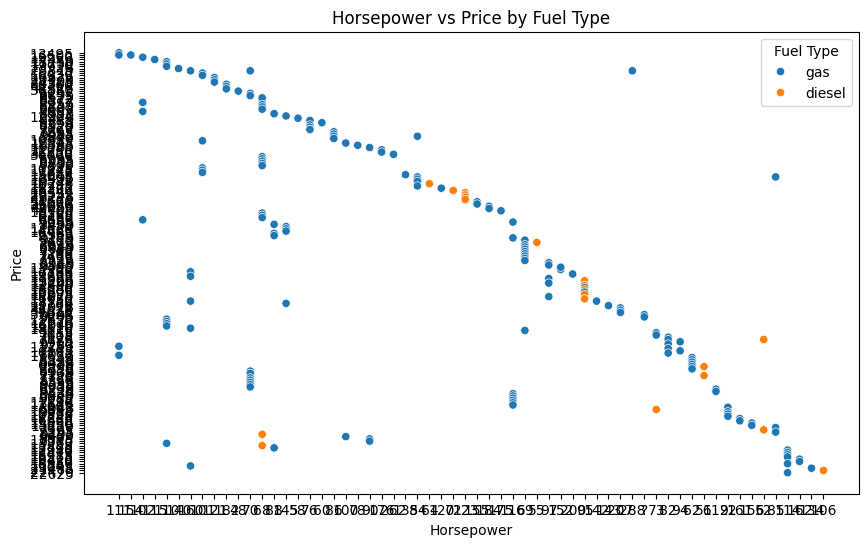

In [9]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='horsepower',
    y='price',
    hue='fuel-type'
)

plt.title('Horsepower vs Price by Fuel Type')
plt.xlabel('Horsepower')
plt.ylabel('Price')
plt.legend(title='Fuel Type')
plt.show()

# Engine Size vs City MPG

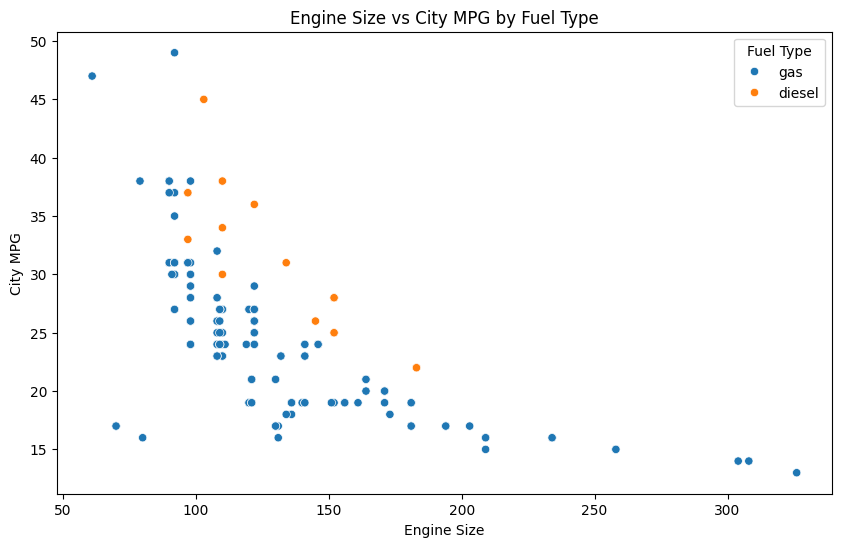

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='engine-size',
    y='city-mpg',
    hue='fuel-type'
)

plt.title('Engine Size vs City MPG by Fuel Type')
plt.xlabel('Engine Size')
plt.ylabel('City MPG')
plt.legend(title='Fuel Type')
plt.show()

# Price Distribution by Body Style

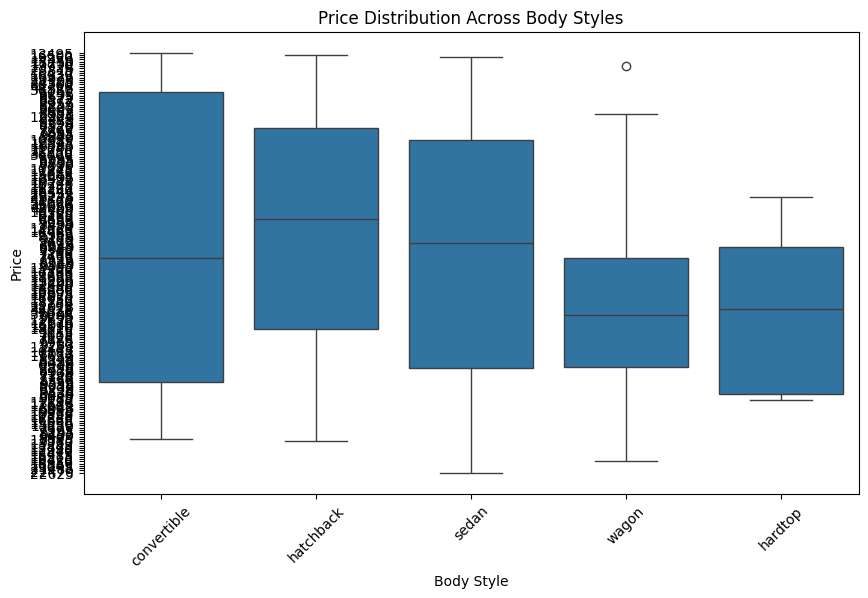

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='body-style',
    y='price'
)

plt.title('Price Distribution Across Body Styles')
plt.xlabel('Body Style')
plt.ylabel('Price')
plt.xticks(rotation=45)

plt.show()

# Price by Fuel Type and Engine Type

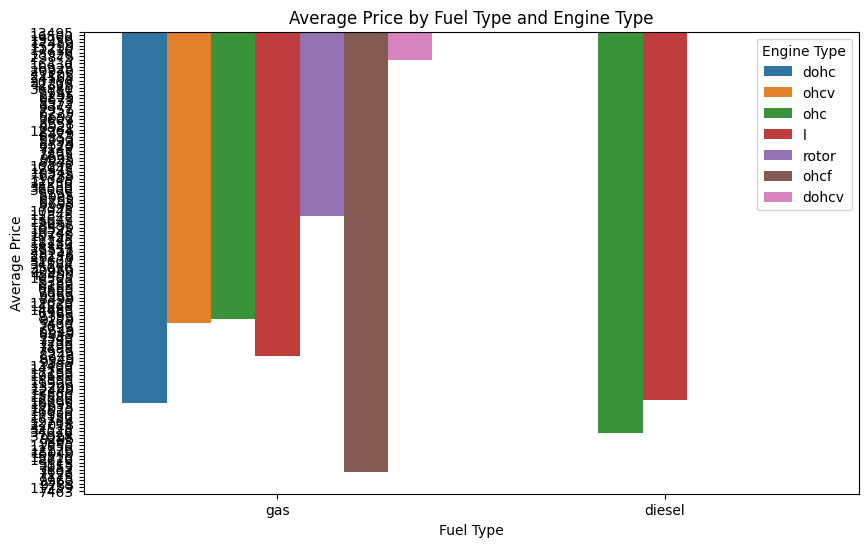

In [12]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='fuel-type',
    y='price',
    hue='engine-type',
    errorbar=None
)

plt.title('Average Price by Fuel Type and Engine Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Price')
plt.legend(title='Engine Type')

plt.show()

#  Correlation Heatmap

 Select numerical columns

In [21]:

correlation_columns = [
    'engine-size',
    'horsepower',
    'curb-weight',
    'wheel-base',
    'length',
    'width',
    'height',
    'city-mpg',
    'highway-mpg',
    'combined_mpg',
    'power_to_weight_ratio',
    'price'
]



In [22]:
print("Available Columns:")
print(df.columns.tolist())

print("\nMissing Required Columns:")
print([col for col in correlation_columns if col not in df.columns])

Available Columns:
['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'combined_mpg', 'power_to_weight_ratio']

Missing Required Columns:
[]


In [23]:
correlation_data = df[correlation_columns].copy()

In [24]:
correlation_data = correlation_data.apply(
    pd.to_numeric, errors='coerce'
)

Calculate correlation

In [25]:
correlation_matrix = df[correlation_columns].corr()

In [26]:
correlation_matrix = correlation_data.corr()

# Create heatmap

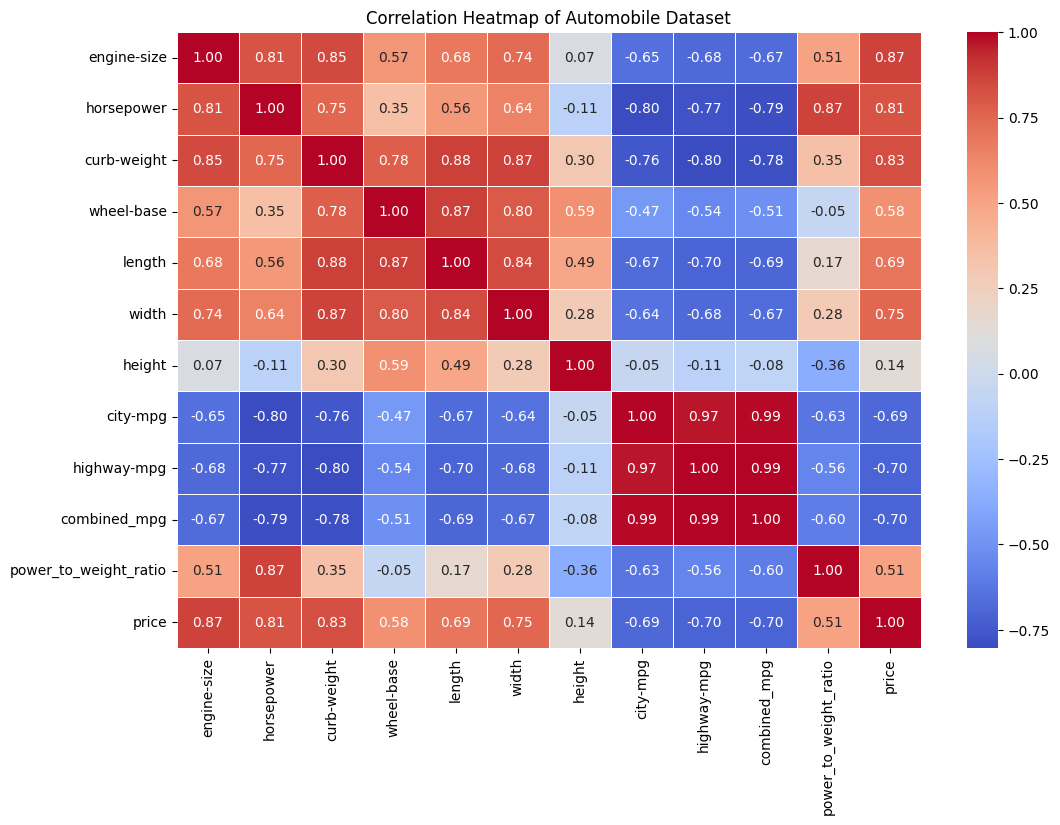

In [27]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Automobile Dataset')
plt.show()

#  Manufacturer-wise Analysis

 Group data by manufacturer

In [28]:
manufacturer_analysis = df.groupby('make').agg({
    'price': 'mean',
    'horsepower': 'mean',
    'combined_mpg': 'mean'
}).reset_index()


In [29]:

print("Manufacturer-wise Average Analysis:")
display(manufacturer_analysis)


Manufacturer-wise Average Analysis:


,make,price,horsepower,combined_mpg
0,alfa-romero,15498.333333,125.333333,23.500000
1,audi,17859.166667,121.000000,21.500000
2,bmw,26118.750000,138.875000,22.375000
3,chevrolet,6007.000000,62.666667,43.666667
4,dodge,7875.444444,86.333333,31.055556
5,honda,8184.692308,80.230769,32.923077
6,isuzu,8916.500000,77.000000,33.500000
7,jaguar,34600.000000,204.666667,16.333333
8,mazda,10652.882353,85.529412,28.823529
9,mercedes-benz,33647.000000,146.250000,19.750000


# Plot average price

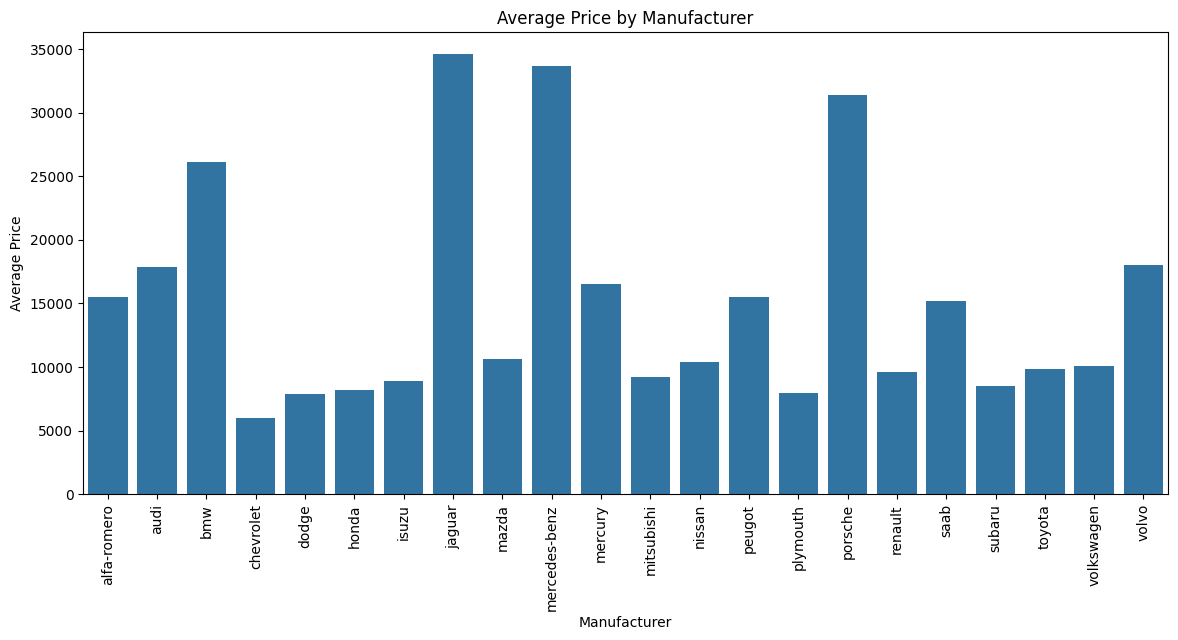

In [30]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=manufacturer_analysis,
    x='make',
    y='price'
)

plt.title('Average Price by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Average Price')
plt.xticks(rotation=90)
plt.show()



In [31]:

print("\nAverage Horsepower and Combined MPG:")
display(manufacturer_analysis[['make', 'horsepower', 'combined_mpg']])


Average Horsepower and Combined MPG:


,make,horsepower,combined_mpg
0,alfa-romero,125.333333,23.500000
1,audi,121.000000,21.500000
2,bmw,138.875000,22.375000
3,chevrolet,62.666667,43.666667
4,dodge,86.333333,31.055556
5,honda,80.230769,32.923077
6,isuzu,77.000000,33.500000
7,jaguar,204.666667,16.333333
8,mazda,85.529412,28.823529
9,mercedes-benz,146.250000,19.750000


#  Bubble Chart


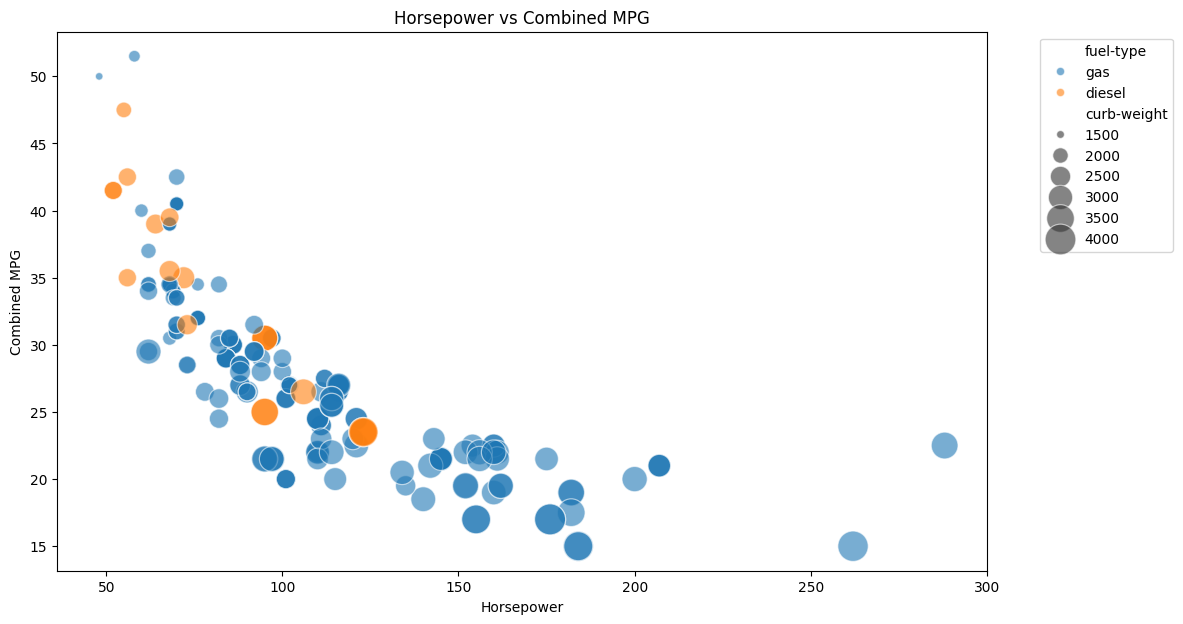

In [32]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='horsepower',
    y='combined_mpg',
    size='curb-weight',
    hue='fuel-type',
    sizes=(30, 500),
    alpha=0.6
)

plt.title('Horsepower vs Combined MPG')
plt.xlabel('Horsepower')
plt.ylabel('Combined MPG')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()